# 20. ARIMA / ARIMAX: forecasting SOH from each battery's own history (Chap 5)

**Author:** Tiến Hưng · **Reviewer:** Quốc Đạt · **Branch:** `tien-hung` · **WBS:** C5.1–C5.7 · **RQ3**

The notebook follows the Box-Jenkins workflow (Chap 5): plot the series → check stationarity → identify (p, d, q) → estimate → residual diagnostics → forecast.
Data, the train/test split and scoring come from `src/protocol.py` (Rec.md sections 6 and 6.1), so the results are comparable with naive, regression, SVR and LSTM.

| Convention | Value |
|---|---|
| Series | `soh` in row order (`cycle_valid` ascending) of each tier-A battery, with `cap_outlier` and `break_in` removed (Rec.md 6.1 #4) |
| Time axis | cycle index, not calendar time, because rest gaps between cycles are irregular (Chap 5, p. 4) |
| Box-Jenkins analysis (sections 1–5) | the 8 **train** batteries, full series; for test batteries only the part before the 60% origin is looked at |
| Forecasting (sections 6–7) | each test battery: fit on its own first 60% of rows, forecast the remaining 40% under E1 and E2 |
| Fitting (all sections) | MLE on SOH in percentage points with `maxiter = 1000`, mapped back to SOH units (section 3); convergence of every fit is recorded |

Run from the repo root or from `notebooks/` (Restart & Run All).

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tools.sm_exceptions import ConvergenceWarning, ValueWarning
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import acf, adfuller

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
from protocol import EOL_SOH, KEYS, PRED, PRED_COLS, evaluate, load_split  # noqa: E402

FIG = ROOT / "reports" / "figures"
TAB = ROOT / "reports" / "tables"
FIG.mkdir(parents=True, exist_ok=True)
TAB.mkdir(parents=True, exist_ok=True)
# The convergence status of every fit is recorded (column `converged` in the AIC grids, in the model
# tables and in reports/tables/arima_orders.csv), so the repeated statsmodels warnings are silenced here.
warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=ValueWarning)
warnings.filterwarnings("ignore", message=".*Non-stationary starting autoregressive.*")
warnings.filterwarnings("ignore", message=".*Non-invertible starting MA.*")
warnings.filterwarnings("ignore", message=".*adfuller currently returns a plain tuple.*", category=FutureWarning)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

train, test = load_split()
rows = pd.concat([train.assign(set="train"), test.assign(set="test")], ignore_index=True)
rows["log_rest"] = np.log1p(rows.rest_before_h)
TRAIN_IDS = sorted(train.battery_id.unique())
TEST_IDS = sorted(test.battery_id.unique())
print(f"train {len(train)} rows / {len(TRAIN_IDS)} batteries; test {len(test)} rows / {len(TEST_IDS)} batteries; "
      f"evaluation rows {int(test.is_eval.sum())}")

train 947 rows / 8 batteries; test 528 rows / 4 batteries; evaluation rows 213


## 1. Plot the SOH series of each tier-A battery (C5.1, Chap 5 pp. 5–6)

The table summarises each series. `n_long_rest` is the number of cycles that follow a long rest (flag `long_rest` in `cycles_clean.csv`).
For test batteries, `n_pre` / `n_eval` are the number of rows before the 60% origin (used for fitting) and the number of evaluation rows.

In [2]:
summary = rows.groupby("battery_id").agg(
    set=("set", "first"), ambient_C=("ambient_C", "first"), I_level_A=("I_level_A", "first"),
    cutoff_V=("discharge_cutoff_V", "first"), n=("soh", "size"),
    soh_first=("soh", "first"), soh_last=("soh", "last"), soh_min=("soh", "min"),
    n_long_rest=("long_rest", "sum"))
pre_eval = test.groupby("battery_id").is_eval.agg(n_pre=lambda s: int((~s).sum()), n_eval="sum")
summary = summary.join(pre_eval)
summary.round(3)

,set,ambient_C,I_level_A,cutoff_V,n,soh_first,soh_last,soh_min,n_long_rest,n_pre,n_eval
battery_id,,,,,,,,,,,
B0005,train,24.0,2.0,2.7,167,1.005,0.717,0.697,8,NaN,NaN
B0006,train,24.0,2.0,2.5,166,1.005,0.591,0.576,8,NaN,NaN
B0007,test,24.0,2.0,2.2,167,1.005,0.763,0.746,8,100.0,67.0
B0018,train,24.0,2.0,2.5,132,1.006,0.733,0.733,0,NaN,NaN
B0033,train,24.0,4.0,2.0,178,1.025,0.786,0.783,5,NaN,NaN
B0034,test,24.0,4.0,2.2,194,1.009,0.808,0.799,6,116.0,78.0
B0045,train,4.0,1.0,2.0,67,1.041,0.727,0.724,6,NaN,NaN
B0046,train,4.0,1.0,2.2,68,1.011,0.795,0.777,6,NaN,NaN
B0047,test,4.0,1.0,2.5,68,1.011,0.776,0.744,6,40.0,28.0


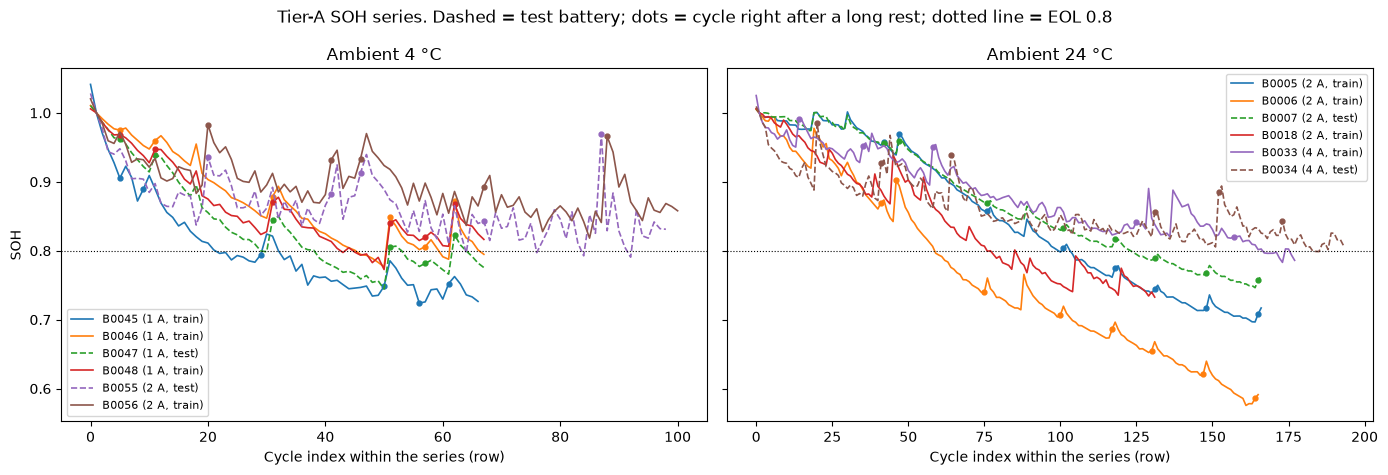

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
for ax, (amb, grp) in zip(axes, rows.groupby("ambient_C")):
    for b, g in grp.groupby("battery_id"):
        style = "-" if g.set.iloc[0] == "train" else "--"
        line, = ax.plot(np.arange(len(g)), g.soh, style, lw=1.2,
                        label=f"{b} ({g.I_level_A.iloc[0]:.0f} A, {g.set.iloc[0]})")
        lr = np.flatnonzero(g.long_rest.values)
        ax.plot(lr, g.soh.values[lr], "o", ms=3.5, color=line.get_color())
    ax.axhline(EOL_SOH, color="k", lw=0.8, ls=":")
    ax.set_title(f"Ambient {amb:.0f} °C")
    ax.set_xlabel("Cycle index within the series (row)")
    ax.legend(fontsize=8)
axes[0].set_ylabel("SOH")
fig.suptitle("Tier-A SOH series. Dashed = test battery; dots = cycle right after a long rest; dotted line = EOL 0.8")
fig.tight_layout()
fig.savefig(FIG / "arima_01_series.png", dpi=150)
plt.show()

**Observations (C5.1):**
- **Trend:** every series declines with cycling, so the raw series is not mean-stationary.
- **Regeneration:** the dots (cycles right after a long rest) usually sit clearly above the previous point, and SOH then drops quickly back to the trend line.
  This is capacity regeneration after rest (F5), which is why `log1p(rest_before_h)` enters ARIMAX in section 6.
- **Seasonality:** long rests happen at irregular positions, so no fixed repeating period is visible. Section 5 checks this again with the ACF.

## 2. Stationarity: ADF and ACF (C5.2, Chap 5 pp. 11–14, p. 71)

ADF test, H0: the series has a unit root (non-stationary). Run on the level series with two regression forms, `c` (constant) and `ct` (constant + trend),
then on the first difference `Δsoh` with form `c`. Lag length chosen by AIC (`autolag="AIC"`).
Train batteries use the full series; test batteries use only the part before the 60% origin (exactly the data that is fitted).

In [4]:
def pre_origin(b):
    g = rows[rows.battery_id == b]
    return g if g.set.iloc[0] == "train" else g[~g.is_eval.astype(bool)]


adf_rows = []
for b in TRAIN_IDS + TEST_IDS:
    y = pre_origin(b).soh.to_numpy()
    r_c, r_ct, r_d = adfuller(y, regression="c"), adfuller(y, regression="ct"), adfuller(np.diff(y), regression="c")
    adf_rows.append({"battery_id": b, "set": rows.loc[rows.battery_id == b, "set"].iloc[0], "n": len(y),
                     "ADF_level_c": r_c[0], "p_level_c": r_c[1], "ADF_level_ct": r_ct[0], "p_level_ct": r_ct[1],
                     "ADF_diff": r_d[0], "p_diff": r_d[1]})
adf_table = pd.DataFrame(adf_rows)
adf_table["level_stationary_5pct"] = (adf_table.p_level_c < 0.05) & (adf_table.p_level_ct < 0.05)
adf_table["diff_stationary_5pct"] = adf_table.p_diff < 0.05
adf_table.round(4)

,battery_id,set,n,ADF_level_c,p_level_c,ADF_level_ct,p_level_ct,ADF_diff,p_diff,level_stationary_5pct,diff_stationary_5pct
0,B0005,train,167,-0.5349,0.8850,-1.8906,0.6595,-10.6818,0.0,False,True
1,B0006,train,166,-1.4503,0.5580,-2.8460,0.1806,-9.6915,0.0,False,True
2,B0018,train,132,-1.5107,0.5282,-3.4549,0.0445,-8.3744,0.0,False,True
3,B0033,train,178,-1.1482,0.6955,-2.9622,0.1430,-6.0435,0.0,False,True
4,B0045,train,67,-4.2728,0.0005,-4.3472,0.0027,-7.5565,0.0,True,True
5,B0046,train,68,-1.6886,0.4370,-2.9116,0.1585,-7.5728,0.0,False,True
6,B0048,train,68,-2.3247,0.1641,-2.2259,0.4753,-8.8342,0.0,False,True
7,B0056,train,101,-2.5407,0.1059,-5.5342,0.0000,-7.4616,0.0,False,True
8,B0007,test,100,0.1556,0.9697,-2.4257,0.3660,-8.3317,0.0,False,True
9,B0034,test,116,-1.9416,0.3128,-3.9622,0.0099,-8.1040,0.0,False,True


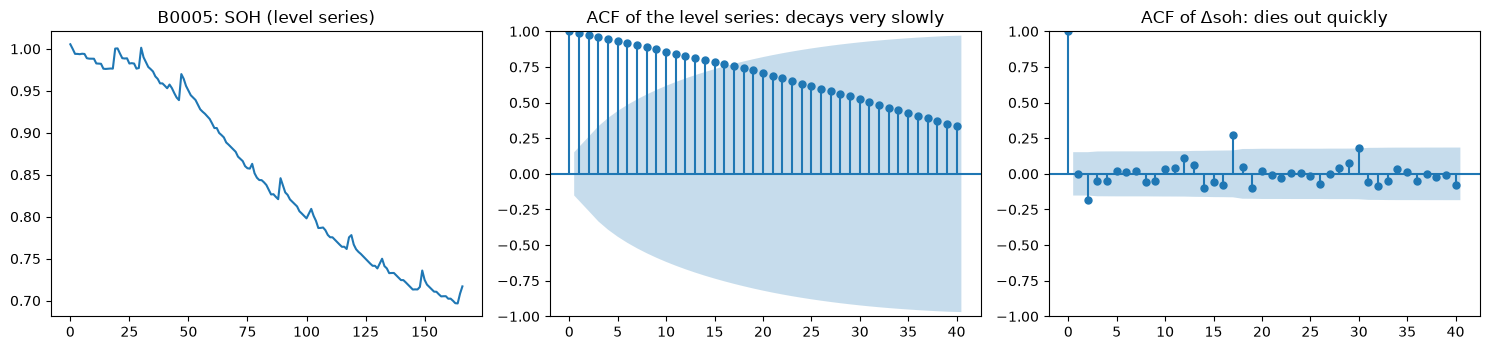

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
y5 = rows.loc[rows.battery_id == "B0005", "soh"].to_numpy()
axes[0].plot(y5)
axes[0].set_title("B0005: SOH (level series)")
plot_acf(y5, lags=40, ax=axes[1], title="ACF of the level series: decays very slowly")
plot_acf(np.diff(y5), lags=40, ax=axes[2], title="ACF of Δsoh: dies out quickly")
fig.tight_layout()
fig.savefig(FIG / "arima_02_acf_level_vs_diff.png", dpi=150)
plt.show()

**Choice of d:** the ACF of the level series decays very slowly, the classic sign of a non-stationary series (p. 13). After first differencing, the ACF dies out almost
immediately and ADF rejects H0 for every battery (column `diff_stationary_5pct`). A few short series also have a level ADF below 0.05 (column `level_stationary_5pct`):
these are short 4 °C batteries with many large regeneration jumps, which make ADF noisy. Because the downward trend is obvious in every series and the level ACF decays
slowly, the team **fixes d = 1 for every battery** so that all batteries share one model form. d = 2 is not needed because `Δsoh` is already stationary.

## 3. Identifying (p, q) with ACF/PACF and an AIC grid (C5.3, Chap 5 pp. 47, 65–67)

Read the ACF/PACF of `Δsoh` on the 8 train batteries: a PACF cut-off after lag p suggests AR(p), an ACF cut-off after lag q suggests MA(q).

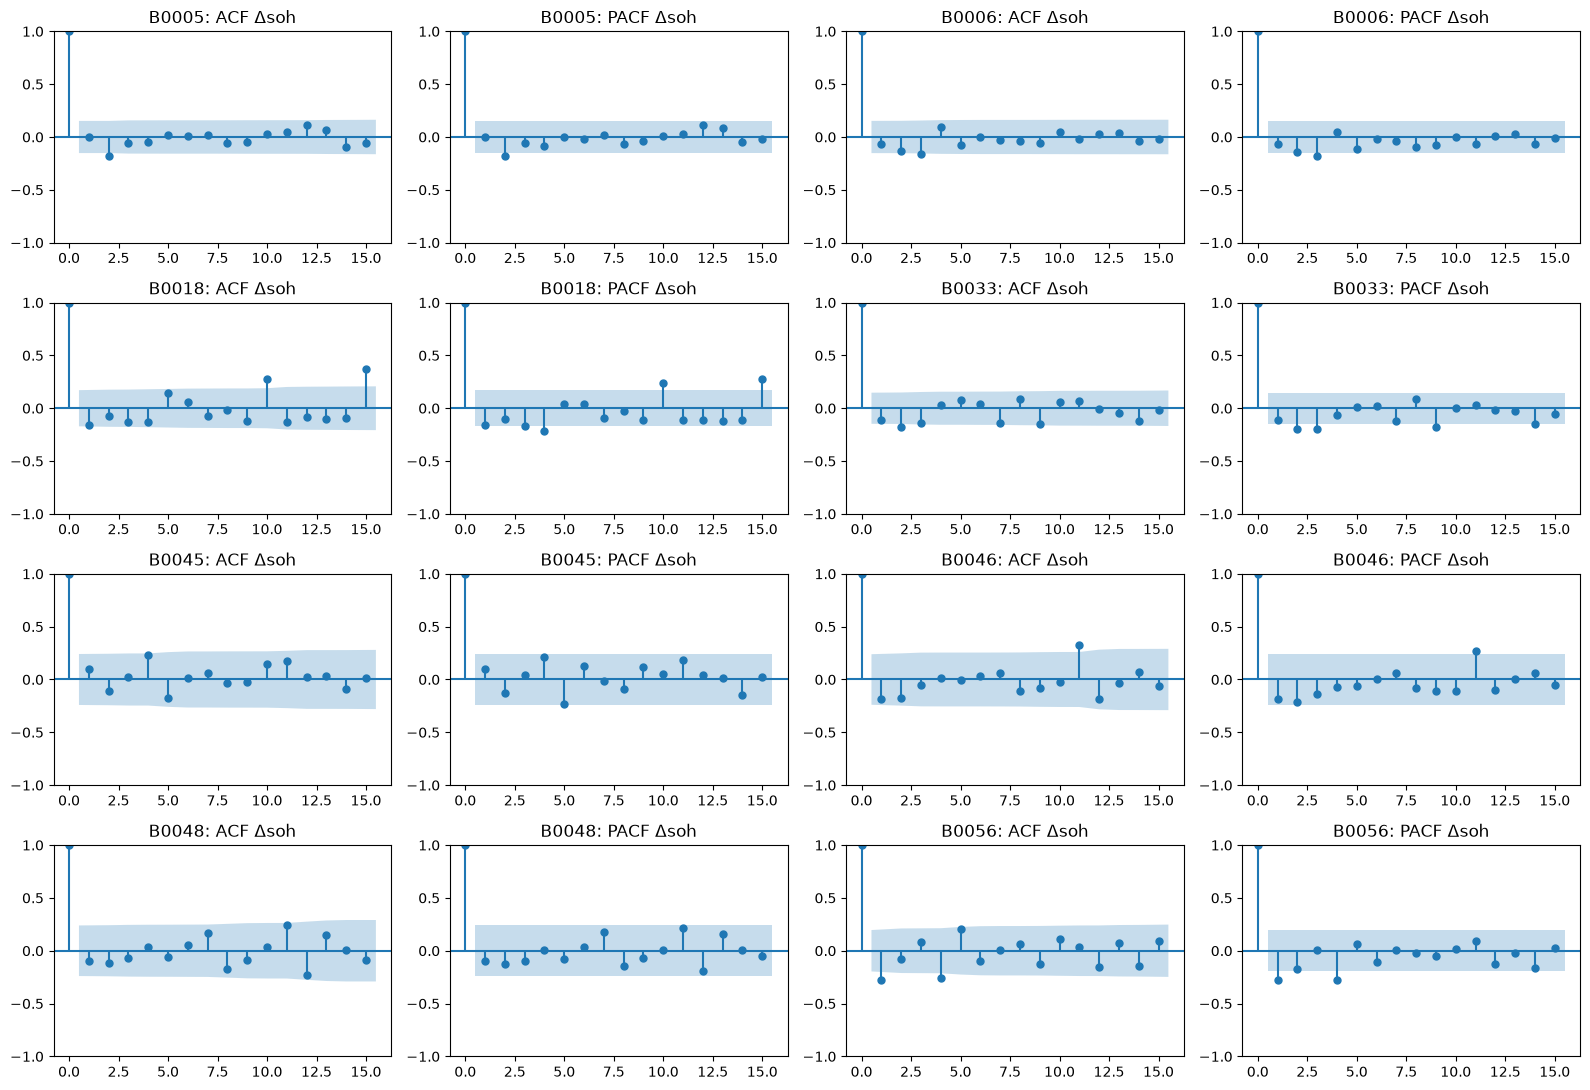

In [6]:
fig, axes = plt.subplots(4, 4, figsize=(16, 11))
for i, b in enumerate(TRAIN_IDS):
    d = np.diff(rows.loc[rows.battery_id == b, "soh"].to_numpy())
    plot_acf(d, lags=15, ax=axes[i // 2, (i % 2) * 2], title=f"{b}: ACF Δsoh")
    plot_pacf(d, lags=15, ax=axes[i // 2, (i % 2) * 2 + 1], title=f"{b}: PACF Δsoh", method="ywm")
fig.tight_layout()
fig.savefig(FIG / "arima_03_acf_pacf_diff.png", dpi=150)
plt.show()

The plots only suggest low orders: the prominent spikes, if any, are usually at lag 1, sometimes lag 2. The grid is therefore **p, q ∈ {0, 1, 2}, d = 1**, chosen by **AIC** (p. 67).
One more choice concerns the constant: `trend="n"` (no drift) and `trend="t"` (drift, i.e. `Δsoh` has a non-zero mean). Drift is the only way an ARIMA with d = 1
can forecast a downward trend many steps ahead (E2); without drift the multi-step forecast is almost flat.

That gives 3 × 3 × 2 = 18 models per series, estimated by MLE (`statsmodels.tsa.arima.model.ARIMA`, p. 48). Only models whose optimiser converged are accepted.

**Numerical settings (reproducibility).** SOH changes by about 0.001–0.01 per cycle, so on the SOH scale the innovation variance is around 1e-5 and the likelihood is badly
scaled for the L-BFGS optimiser. With the default settings (50 iterations, SOH scale) the optimiser often stopped at slightly different points, and its `converged` flag
flipped, when the input changed only at rounding level (1e-12); the selected (p, q) and the forecasts then changed between machines with different numpy/scipy builds.
Every model is therefore fitted as follows:
1. MLE on SOH expressed in **percentage points** (`100 · soh`) with `maxiter = 1000`;
2. the estimates are mapped back to SOH units (AR/MA coefficients unchanged, drift and exogenous coefficients ÷ 100, σ² ÷ 100²) and the Kalman smoother is run on the
   original `soh` series with those parameters, so AIC, residuals, standard errors and forecasts are all in SOH units;
3. `converged` is read from the optimiser of step 1 (`mle_retvals["converged"]`).

Rescaling `y` by a constant shifts the log-likelihood of every model fitted on the same rows by the same amount, so it does not change the AIC ranking; it only makes the
optimisation well conditioned. With this setting, perturbing the input by 1e-12 or 1e-9 (10 random draws) no longer changed any selected order.

In [7]:
GRID = [(p, q, tr) for p in range(3) for q in range(3) for tr in ("n", "t")]
SCALE = 100.0           # fit on SOH in percentage points (see the markdown above)
MAXITER = 1000


def fit_arima(y, order, trend, exog=None):
    # MLE on SCALE*y for numerical stability, returned as a results object in SOH units
    fit_pct = ARIMA(y * SCALE, exog=exog, order=order, trend=trend).fit(method_kwargs={"maxiter": MAXITER})
    model = ARIMA(y, exog=exog, order=order, trend=trend)
    unit = np.array([1.0 if n.startswith(("ar.", "ma.")) else SCALE ** 2 if n == "sigma2" else SCALE
                     for n in model.param_names])
    res = model.smooth(np.asarray(fit_pct.params) / unit)
    res.mle_retvals = fit_pct.mle_retvals
    return res


def aic_grid(y, exog=None):
    out = []
    for p, q, tr in GRID:
        try:
            res = fit_arima(y, (p, 1, q), tr, exog)
            out.append({"p": p, "d": 1, "q": q, "trend": tr, "AIC": res.aic, "BIC": res.bic,
                        "converged": bool(res.mle_retvals.get("converged", True))})
        except Exception as e:  # record the failure instead of skipping it silently
            out.append({"p": p, "d": 1, "q": q, "trend": tr, "AIC": np.nan, "BIC": np.nan, "converged": False,
                        "error": str(e)[:60]})
    return pd.DataFrame(out).sort_values("AIC").reset_index(drop=True)


def best_spec(grid):
    ok = grid[grid.converged & grid.AIC.notna()]
    top = ok.iloc[0]
    return (int(top.p), 1, int(top.q)), top.trend


grids = {b: aic_grid(rows.loc[rows.battery_id == b, "soh"].to_numpy()) for b in TRAIN_IDS}
print("Full AIC grid of B0005 (sorted by AIC):")
grids["B0005"].round(2)

Full AIC grid of B0005 (sorted by AIC):


,p,d,q,trend,AIC,BIC,converged,error
0,0,1,2,t,-1229.56,-1217.11,True,NaN
1,2,1,0,t,-1228.33,-1215.88,True,NaN
2,1,1,2,t,-1228.21,-1212.65,True,NaN
3,2,1,1,t,-1227.98,-1212.42,True,NaN
4,0,1,0,t,-1226.40,-1220.17,True,NaN
5,2,1,2,t,-1226.23,-1207.55,True,NaN
6,1,1,1,t,-1225.99,-1213.54,True,NaN
7,0,1,1,t,-1224.40,-1215.07,True,NaN
8,1,1,0,t,-1224.40,-1215.06,True,NaN
9,0,1,0,n,-1214.79,-1211.68,True,NaN


In [8]:
train_specs = []
for b in TRAIN_IDS:
    g = grids[b]
    order, tr = best_spec(g)
    second = g[g.converged].iloc[1]
    train_specs.append({"battery_id": b, "n": int((rows.battery_id == b).sum()), "p": order[0], "d": 1, "q": order[2],
                        "trend": tr, "AIC": g[g.converged].AIC.iloc[0],
                        "AIC_2nd": second.AIC, "2nd": f"({int(second.p)},1,{int(second.q)}) {second.trend}",
                        "n_not_converged": int((~g.converged).sum())})
train_specs = pd.DataFrame(train_specs)
train_specs.round(2)

,battery_id,n,p,d,q,trend,AIC,AIC_2nd,2nd,n_not_converged
0,B0005,167,0,1,2,t,-1229.56,-1228.33,"(2,1,0) t",1
1,B0006,166,1,1,1,t,-1052.17,-1051.24,"(2,1,1) t",0
2,B0018,132,1,1,1,t,-796.18,-794.28,"(2,1,1) t",0
3,B0033,178,1,1,1,t,-1086.15,-1085.58,"(2,1,1) t",0
4,B0045,67,2,1,2,t,-364.67,-363.87,"(0,1,0) t",0
5,B0046,68,0,1,2,t,-349.31,-348.97,"(1,1,1) t",0
6,B0048,68,0,1,0,t,-363.05,-362.90,"(0,1,0) n",0
7,B0056,101,1,1,1,t,-450.02,-449.38,"(2,1,2) t",0


## 4. Residual diagnostics: ACF and Ljung-Box (C5.4, Chap 5 p. 49)

A good model leaves white-noise residuals. **Ljung-Box** test (beyond the slides), H0: no residual autocorrelation up to lag h.
Run at h = 10 and h = 20, with the degrees of freedom reduced by p + q (`model_df`). The first residual is dropped because with d = 1 it is only the initial value (the first `soh` itself).

**Final selection rule** (the Box-Jenkins loop, p. 49 "if not adequate, go back to identification"): walk through the grid in increasing AIC order and take the **first**
model that both converged and has Ljung-Box p > 0.05 at lags 10 and 20. If no model passes, keep the lowest-AIC converged model and flag it `LB_pass = False`.
The same rule is reused unchanged for the test batteries in section 6.

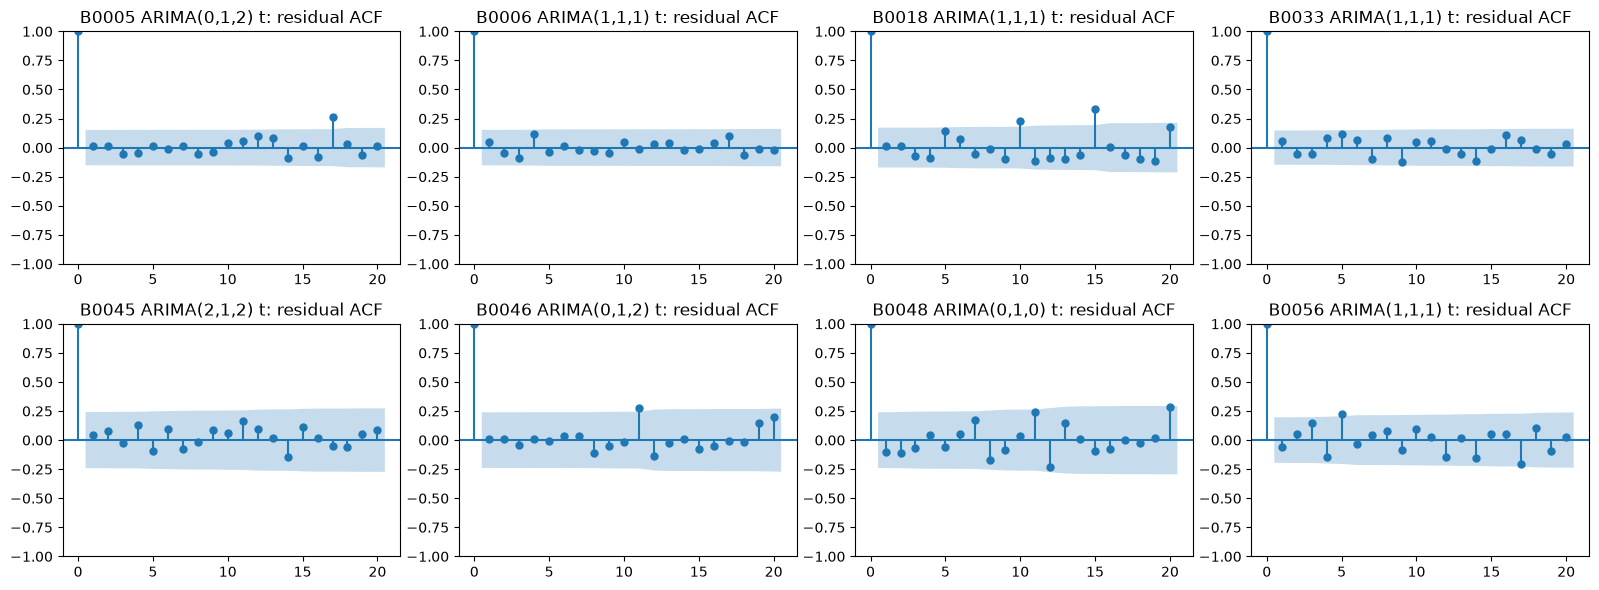

,battery_id,n_fit,p,d,q,trend,AIC,LB_p_lag10,LB_p_lag20,aic_rank,LB_pass,converged,resid_sd
0,B0005,167,0,1,2,t,-1229.5589,0.9793,0.2136,1,True,True,0.0058
1,B0006,166,1,1,1,t,-1052.1711,0.6584,0.9470,1,True,True,0.0098
2,B0018,132,1,1,1,t,-796.1840,0.0608,0.0003,1,False,True,0.0113
3,B0033,178,1,1,1,t,-1086.1503,0.1393,0.3021,1,True,True,0.0110
4,B0045,67,2,1,2,t,-364.6748,0.5825,0.7348,1,True,True,0.0142
5,B0046,68,0,1,2,t,-349.3117,0.9915,0.5910,1,True,True,0.0169
6,B0048,68,0,1,0,t,-363.0527,0.6439,0.1020,1,True,True,0.0158
7,B0056,101,1,1,1,t,-450.0217,0.1051,0.0794,1,True,True,0.0244


In [9]:
def ljung_box(res, p, q, lags=(10, 20)):
    resid = np.asarray(res.resid)[1:]
    lb = acorr_ljungbox(resid, lags=list(lags), model_df=p + q)
    return {f"LB_p_lag{h}": lb.loc[h, "lb_pvalue"] for h in lags}


def select(y, exog=None, grid=None):
    # Return (res, order, trend, info): lowest-AIC converged model whose residuals pass Ljung-Box
    grid = aic_grid(y, exog) if grid is None else grid
    ok = grid[grid.converged & grid.AIC.notna()].reset_index(drop=True)
    first = None
    for rank, r in ok.iterrows():
        order, tr = (int(r.p), 1, int(r.q)), r.trend
        res = fit_arima(y, order, tr, exog)
        lb = ljung_box(res, order[0], order[2])
        passed = all(v > 0.05 for v in lb.values())
        info = {**lb, "aic_rank": rank + 1, "LB_pass": passed,
                "converged": bool(res.mle_retvals.get("converged", True))}
        first = first or (res, order, tr, info)
        if passed:
            return res, order, tr, info
    return first


diag = []
chosen = {}
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for ax, b in zip(axes.flat, TRAIN_IDS):
    y = rows.loc[rows.battery_id == b, "soh"].to_numpy()
    res, order, tr, info = select(y, grid=grids[b])
    chosen[b] = (order, tr)
    diag.append({"battery_id": b, "n_fit": len(y), "p": order[0], "d": 1, "q": order[2], "trend": tr, "AIC": res.aic,
                 **info, "resid_sd": np.std(np.asarray(res.resid)[1:], ddof=1)})
    plot_acf(np.asarray(res.resid)[1:], lags=20, ax=ax,
             title=f"{b} ARIMA({order[0]},1,{order[2]}) {tr}: residual ACF")
fig.tight_layout()
fig.savefig(FIG / "arima_04_resid_acf_train.png", dpi=150)
plt.show()
diag = pd.DataFrame(diag)
diag.round(4)

`aic_rank = 1` means the lowest-AIC converged model already passed the diagnostics. `aic_rank > 1` means the lowest-AIC model still had autocorrelated residuals,
so the loop went back to the grid and took the next model that passes (compare with the table in section 3). `converged` is the optimiser status of the final model.

## 5. Is SARIMA needed? Seasonality and regeneration (C5.6, Chap 5 pp. 60–62)

SARIMA only helps when the series repeats after a fixed number of cycles s. Two checks:
1. ACF of `Δsoh` up to lag 40 on the 8 train batteries: does any lag (other than lags 1–2) exceed the 95% band in **many batteries at once**?
2. Is the gap (number of cycles) between two consecutive long rests constant? If not, the regeneration "saw-teeth" are not seasonal.

In [10]:
LAGS = 40
sig = {}
for b in TRAIN_IDS:
    d = np.diff(rows.loc[rows.battery_id == b, "soh"].to_numpy())
    r = acf(d, nlags=LAGS)
    band = 1.96 / np.sqrt(len(d))
    sig[b] = np.abs(r[1:]) > band
sig = pd.DataFrame(sig, index=range(1, LAGS + 1))
count = sig.sum(axis=1)
print("Number of train batteries (out of 8) whose ACF(Δsoh) exceeds the ±1.96/√n band, by lag:")
print(count[count > 0].to_string())

gaps = []
for b in TRAIN_IDS:
    pos = np.flatnonzero(rows.loc[rows.battery_id == b, "long_rest"].to_numpy())
    gaps.append({"battery_id": b, "n_long_rest": len(pos), "gaps_between_long_rests": np.diff(pos).tolist()})
pd.DataFrame(gaps)

Number of train batteries (out of 8) whose ACF(Δsoh) exceeds the ±1.96/√n band, by lag:
1     1
2     2
3     1
4     1
5     1
9     1
10    1
11    2
15    1
17    2
20    2
21    1
25    1
26    1
27    1
30    2
35    1
40    1


,battery_id,n_long_rest,gaps_between_long_rests
0,B0005,8,"[5, 29, 25, 17, 13, 17, 17]"
1,B0006,8,"[5, 29, 25, 17, 13, 17, 17]"
2,B0018,0,[]
3,B0033,5,"[21, 23, 67, 32]"
4,B0045,6,"[4, 20, 21, 6, 5]"
5,B0046,6,"[6, 20, 20, 6, 5]"
6,B0048,6,"[6, 20, 20, 6, 5]"
7,B0056,5,"[21, 5, 21, 21]"


In [11]:
reg = []
for b in TRAIN_IDS:
    g = rows[rows.battery_id == b]
    d = np.diff(g.soh.to_numpy())
    x = g.log_rest.to_numpy()[1:]
    lr = g.long_rest.to_numpy()[1:]
    reg.append({"battery_id": b, "n_long_rest": int(lr.sum()),
                "corr(Δsoh_t, log1p(rest_before_h)_t)": np.corrcoef(d, x)[0, 1],
                "mean Δsoh after long rest": d[lr].mean() if lr.any() else np.nan,
                "mean Δsoh otherwise": d[~lr].mean()})
pd.DataFrame(reg).round(4)

,battery_id,n_long_rest,"corr(Δsoh_t, log1p(rest_before_h)_t)",mean Δsoh after long rest,mean Δsoh otherwise
0,B0005,8,0.3779,0.0094,-0.0023
1,B0006,8,0.2856,0.0121,-0.0033
2,B0018,0,-0.1078,NaN,-0.0021
3,B0033,5,0.5091,0.0264,-0.0022
4,B0045,6,0.2790,0.0024,-0.0055
5,B0046,6,0.7200,0.0336,-0.0068
6,B0048,6,0.7806,0.0326,-0.0063
7,B0056,5,0.6200,0.0639,-0.0051


B0018 has no long rest (`n_long_rest = 0`), yet the plot in section 1 still shows jumps. The table below counts the **jumps** (`Δsoh > 0.015`) of each battery and checks whether
they come right after a new EIS measurement (`eis_op_index` changes from the previous row) or after a long rest. The 0.015 threshold is about twice the largest residual
standard deviation of the 24 °C batteries in the section 4 table, so only clear jumps are counted.

In [12]:
JUMP = 0.015
jump_rows = []
for b in TRAIN_IDS + TEST_IDS:
    g = pre_origin(b).reset_index(drop=True)          # test batteries: only the part before the origin
    big = set((np.flatnonzero(np.diff(g.soh.to_numpy()) > JUMP) + 1).tolist())
    new_eis = set(np.flatnonzero(g.eis_op_index.diff().fillna(0).to_numpy() != 0).tolist())
    lr = set(np.flatnonzero(g.long_rest.to_numpy()).tolist())
    jump_rows.append({"battery_id": b, "n": len(g), "n_new_EIS": len(new_eis), "n_jumps": len(big),
                      "jumps_after_new_EIS": len(big & new_eis), "jumps_after_long_rest": len(big & lr),
                      "jumps_after_neither": len(big - new_eis - lr)})
pd.DataFrame(jump_rows)

,battery_id,n,n_new_EIS,n_jumps,jumps_after_new_EIS,jumps_after_long_rest,jumps_after_neither
0,B0005,167,139,5,3,1,1
1,B0006,166,138,5,2,1,2
2,B0018,132,48,9,8,0,1
3,B0033,178,41,7,6,3,1
4,B0045,67,18,7,6,2,1
5,B0046,68,18,4,3,3,1
6,B0048,68,18,5,4,4,1
7,B0056,101,23,24,13,5,10
8,B0007,100,76,4,2,1,1
9,B0034,116,26,9,9,3,0


In B0018 the jumps go with EIS measurements, not with rest time (the recorded rest before those cycles is very short), so `log1p(rest_before_h)` cannot explain them.
This is the most plausible reason why the B0018 residuals are still autocorrelated in section 4 (the jumps are fairly evenly spaced). In B0005–B0007, EIS is measured
almost every cycle, so a "just measured EIS" flag would not discriminate anything there. This observation is passed to the team as a possible improvement (a "just measured EIS"
flag); it is **not** added to the exported model, because the ARIMAX variable list is fixed in Go.md 5b.8.

**C5.6 conclusion** (read together with the tables above):
- No seasonal lag stands out in most batteries; the lags that exceed the band are scattered, each in only a few batteries, as expected by chance when 40 lags are tested at 5%.
- The gap between long rests varies within and between batteries, so there is no fixed period s to put into SARIMA.
- The saw-teeth are tied to rest time instead: `Δsoh` right after a long rest is positive and much larger than in other cycles, and it correlates positively with `log1p(rest_before_h)`.

⇒ **SARIMA is not used.** This systematic variation is modelled with the exogenous variable `log1p(rest_before_h)` in ARIMAX (section 6), as planned in Go.md 5b.8–5b.9.

## 6. Estimation on the test batteries, ARIMA and ARIMAX (C5.3–C5.5, Chap 5 pp. 48–53)

For each test battery the procedure above is repeated **using only the first 60% of rows** of that battery (`is_eval == False`), then the last 40% is forecast.

| Model | Exogenous `x_t` | Reason |
|---|---|---|
| `arima` | none | SOH history only (RQ3) |
| `arimax_rest` | `log1p(rest_before_h)` | explains the regeneration jumps (section 5) |
| `arimax` | `log1p(rest_before_h)`, `Rct_ohm` | as in Go.md 5b.8: adds the charge-transfer resistance from the latest EIS before cycle t |

Common rules (Rec.md 6.1):
- `rest_before_h` of cycle t is the rest **before** discharge t, so it is known at forecast time; `Rct_ohm` comes from an earlier measurement. Both are on the allowed list (Go.md 4.6).
- `Rct_ohm` is missing for the first 19 cycles of B0007 (no EIS measurement yet). Following Rec.md 6.1 #6, **those rows are dropped, not imputed**. So that AIC is comparable across the
  three models, all three B0007 models are fitted on the same rows (from row 20 on). The other three test batteries have no missing values.
- (p, q, trend) are chosen with the AIC grid of section 3, separately for each battery and each model, on the pre-origin rows only. Evaluation data is never used for model choice.

In [13]:
SPECS = {"arima": [], "arimax_rest": ["log_rest"], "arimax": ["log_rest", "Rct_ohm"]}
NEED = ["log_rest", "Rct_ohm"]          # same fitting sample for all three models (Rec.md 6.1 #6)

fits = {}
spec_rows = []
for b in TEST_IDS:
    g = rows[rows.battery_id == b].reset_index(drop=True)
    is_eval = g.is_eval.astype(bool).to_numpy()
    first_ok = int(np.flatnonzero(g[NEED].notna().all(axis=1).to_numpy())[0])
    g = g.iloc[first_ok:].reset_index(drop=True)
    is_eval = is_eval[first_ok:]
    n_pre = int((~is_eval).sum())
    assert g[NEED].notna().all().all() and not is_eval[:n_pre].any() and is_eval[n_pre:].all()
    for name, cols in SPECS.items():
        y_pre = g.soh.iloc[:n_pre]
        x_pre = g[cols].iloc[:n_pre] if cols else None   # DataFrame, so parameters carry the column names
        res, order, tr, info = select(y_pre, x_pre)
        fits[(b, name)] = {"g": g, "n_pre": n_pre, "cols": cols, "res": res, "order": order, "trend": tr}
        par = dict(zip(res.param_names, res.params))
        pv = dict(zip(res.param_names, res.pvalues))
        trend_name = [k for k in par if k not in cols and not k.startswith(("ar.", "ma.", "sigma2"))]
        row = {"battery_id": b, "model": name, "rows_dropped": first_ok, "n_fit": n_pre,
               "p": order[0], "d": 1, "q": order[2], "trend": tr, "AIC": res.aic, **info,
               "drift": par[trend_name[0]] if trend_name else 0.0}
        for c in cols:
            row[f"coef_{c}"], row[f"p_{c}"] = par[c], pv[c]
        spec_rows.append(row)
spec_table = pd.DataFrame(spec_rows)
spec_table.round(4)

,battery_id,model,rows_dropped,n_fit,p,d,q,trend,AIC,LB_p_lag10,LB_p_lag20,aic_rank,LB_pass,converged,drift,coef_log_rest,p_log_rest,coef_Rct_ohm,p_Rct_ohm
0,B0007,arima,19,81,1,1,1,t,-623.1574,0.5514,0.5635,1,True,True,-0.0022,NaN,NaN,NaN,NaN
1,B0007,arimax_rest,19,81,1,1,1,t,-622.8974,0.5073,0.6623,1,True,True,-0.0022,0.0014,0.0193,NaN,NaN
2,B0007,arimax,19,81,1,1,1,t,-631.3773,0.5952,0.9177,1,True,True,-0.0024,0.0010,0.1204,1.1787,0.0000
3,B0034,arima,0,116,2,1,2,t,-607.6296,0.8851,0.6929,1,True,True,-0.0016,NaN,NaN,NaN,NaN
4,B0034,arimax_rest,0,116,2,1,2,t,-673.3063,0.6032,0.4981,1,True,True,-0.0015,0.0119,0.0000,NaN,NaN
5,B0034,arimax,0,116,2,1,2,n,-675.5890,0.2568,0.3152,1,True,True,0.0000,0.0115,0.0000,2.4768,0.1123
6,B0047,arima,0,40,0,1,0,t,-229.4850,0.6708,0.2400,1,True,True,-0.0057,NaN,NaN,NaN,NaN
7,B0047,arimax_rest,0,40,0,1,0,t,-236.4028,0.7415,0.5494,1,True,True,-0.0056,0.0038,0.0000,NaN,NaN
8,B0047,arimax,0,40,0,1,0,t,-236.0496,0.2809,0.1602,1,True,True,-0.0050,0.0039,0.0000,-0.4535,0.2762
9,B0055,arima,0,59,0,1,1,n,-255.2944,0.9711,0.8229,1,True,True,0.0000,NaN,NaN,NaN,NaN


The table above is the per-battery model table (p, d, q, AIC) required by Go.md 5b.
- `drift`: average SOH change per cycle learned by the model (0 when `trend = n`).
- `coef_*` / `p_*`: coefficient and p-value (MLE z-test) of each exogenous variable. With d = 1, statsmodels puts the exogenous variables in the **level** equation (regression with ARIMA errors),
  so a positive `log_rest` coefficient means that a cycle after a longer rest has higher SOH, and SOH falls back once rest returns to normal: exactly the regeneration saw-tooth.
- `LB_p_lag*`, `aic_rank`, `LB_pass`: residual diagnostics of section 4, on the fitting sample. `converged`: optimiser status of the final model.

The selected orders of every final model (8 train batteries from section 4 and 4 test batteries × 3 models from this section) are saved to `reports/tables/arima_orders.csv`,
so that a re-run can be compared order by order.

In [14]:
ORDER_COLS = ["set", "battery_id", "model", "n_fit", "p", "d", "q", "trend", "AIC", "converged",
              "LB_p_lag10", "LB_p_lag20", "LB_pass", "aic_rank"]
orders = pd.concat([diag.assign(set="train", model="arima"), spec_table.assign(set="test")],
                   ignore_index=True)[ORDER_COLS]
orders.to_csv(TAB / "arima_orders.csv", index=False)
print(f"{len(orders)} rows -> {(TAB / 'arima_orders.csv').relative_to(ROOT).as_posix()}; "
      f"all final models converged: {bool(orders.converged.all())}")
orders.round(4)

20 rows -> reports/tables/arima_orders.csv; all final models converged: True


,set,battery_id,model,n_fit,p,d,q,trend,AIC,converged,LB_p_lag10,LB_p_lag20,LB_pass,aic_rank
0,train,B0005,arima,167,0,1,2,t,-1229.5589,True,0.9793,0.2136,True,1
1,train,B0006,arima,166,1,1,1,t,-1052.1711,True,0.6584,0.9470,True,1
2,train,B0018,arima,132,1,1,1,t,-796.1840,True,0.0608,0.0003,False,1
3,train,B0033,arima,178,1,1,1,t,-1086.1503,True,0.1393,0.3021,True,1
4,train,B0045,arima,67,2,1,2,t,-364.6748,True,0.5825,0.7348,True,1
5,train,B0046,arima,68,0,1,2,t,-349.3117,True,0.9915,0.5910,True,1
6,train,B0048,arima,68,0,1,0,t,-363.0527,True,0.6439,0.1020,True,1
7,train,B0056,arima,101,1,1,1,t,-450.0217,True,0.1051,0.0794,True,1
8,test,B0007,arima,81,1,1,1,t,-623.1574,True,0.5514,0.5635,True,1
9,test,B0007,arimax_rest,81,1,1,1,t,-622.8974,True,0.5073,0.6623,True,1


## 7. Forecasts under the common protocol, E1 and E2 (C5.7, Chap 5 p. 49)

- **E1 (one step, rolling):** keep the parameters estimated on the first 60%, run the Kalman filter over the whole series (`res.apply(..., refit=False)`) and take the
  one-step prediction for each evaluation row. The prediction at t uses `soh` only up to t−1 (and `x_t`, which is known before the discharge). Parameters are not re-estimated at each step,
  so the model does not "learn" from evaluation data; this is the same condition as SVR/LSTM (fit once, predict many times).
- **E2 (multi-step from the 60% origin):** `get_forecast` straight to the end of the series. Exogenous variables are held at their last value before the origin (Rec.md 6.1 #5).
- Both scenarios export the 95% prediction interval in `y_lower`, `y_upper`.

In [15]:
def forecasts(f):
    g, n_pre, cols, res = f["g"], f["n_pre"], f["cols"], f["res"]
    y_all = g.soh
    x_all = g[cols] if cols else None
    n_eval = len(g) - n_pre
    one = res.apply(y_all, exog=x_all, refit=False).get_prediction(start=n_pre, end=len(g) - 1).summary_frame(alpha=0.05)
    x_hold = (pd.DataFrame(np.repeat(x_all.iloc[[n_pre - 1]].to_numpy(), n_eval, axis=0), columns=cols,
                           index=range(n_pre, len(g))) if cols else None)
    multi = res.get_forecast(steps=n_eval, exog=x_hold).summary_frame(alpha=0.05)
    ev = g.iloc[n_pre:]
    out = []
    for scenario, sf in (("E1", one), ("E2", multi)):
        out.append(pd.DataFrame({"battery_id": ev.battery_id.to_numpy(), "cycle_valid": ev.cycle_valid.to_numpy(),
                                 "scenario": scenario, "y_true": ev.soh.to_numpy(), "y_pred": sf["mean"].to_numpy(),
                                 "y_lower": sf["mean_ci_lower"].to_numpy(), "y_upper": sf["mean_ci_upper"].to_numpy()}))
    return pd.concat(out, ignore_index=True)


all_pred = pd.concat([forecasts(f).assign(model=name) for (b, name), f in fits.items()], ignore_index=True)[PRED_COLS]
metrics, rul = evaluate(all_pred)        # evaluate() checks the 213 evaluation rows and y_true = soh for every model
naive_pred = pd.read_csv(PRED / "naive.csv")
naive_metrics, naive_rul = evaluate(naive_pred)
metrics = pd.concat([naive_metrics, metrics], ignore_index=True)
rul = pd.concat([naive_rul, rul], ignore_index=True)

pooled = metrics[metrics.battery_id == "all"].pivot(index="model", columns="scenario", values=["MAE", "RMSE", "MAPE_pct", "R2"])
pooled = pooled.loc[["naive", "arima", "arimax_rest", "arimax"]]
pooled.round(4)

MAE            RMSE         MAPE_pct              R2        
scenario         E1      E2      E1      E2       E1      E2      E1      E2
model                                                                       
naive        0.0119  0.0249  0.0226  0.0343   1.4288  3.1271  0.5001 -0.1552
arima        0.0114  0.0468  0.0203  0.0594   1.3851  5.7882  0.5981 -2.4560
arimax_rest  0.0108  0.0456  0.0172  0.0579   1.3077  5.6440  0.7089 -2.2867
arimax       0.0098  0.0407  0.0171  0.0583   1.1820  5.0304  0.7145 -2.3263

In [16]:
per_bat = metrics[metrics.battery_id != "all"].pivot_table(index=["scenario", "battery_id"], columns="model", values="RMSE")
per_bat = per_bat[["naive", "arima", "arimax_rest", "arimax"]]
print("RMSE by battery (rows) and model (columns)")
per_bat.round(4)

RMSE by battery (rows) and model (columns)


model                 naive   arima  arimax_rest  arimax
scenario battery_id                                     
E1       B0007       0.0037  0.0082       0.0082  0.0052
         B0034       0.0135  0.0131       0.0115  0.0121
         B0047       0.0172  0.0180       0.0145  0.0139
         B0055       0.0462  0.0389       0.0326  0.0330
E2       B0007       0.0515  0.0397       0.0396  0.0430
         B0034       0.0179  0.0687       0.0654  0.0185
         B0047       0.0199  0.0923       0.0916  0.0811
         B0055       0.0305  0.0313       0.0320  0.0985

In [17]:
cover = all_pred.assign(inside=(all_pred.y_true >= all_pred.y_lower) & (all_pred.y_true <= all_pred.y_upper),
                        width=all_pred.y_upper - all_pred.y_lower)
coverage = cover.groupby(["model", "scenario"]).agg(coverage_95=("inside", "mean"), mean_width=("width", "mean"))
print("Share of true values inside the 95% prediction interval, and mean interval width")
coverage.round(3)

Share of true values inside the 95% prediction interval, and mean interval width


coverage_95  mean_width
model       scenario                         
arima       E1              0.901       0.054
            E2              0.709       0.185
arimax      E1              0.920       0.045
            E2              0.709       0.178
arimax_rest E1              0.887       0.046
            E2              0.681       0.178

In [18]:
print("E2 RUL error (first cycle with SOH < 0.8; rul_error > 0 = late warning; NaN = the forecast never reaches 0.8 within the data)")
rul.round(1)

E2 RUL error (first cycle with SOH < 0.8; rul_error > 0 = late warning; NaN = the forecast never reaches 0.8 within the data)


,model,battery_id,eol_true,eol_pred,rul_error
0,naive,B0007,126.0,NaN,NaN
1,naive,B0034,186.0,NaN,NaN
2,naive,B0055,65.0,NaN,NaN
3,arima,B0007,126.0,114.0,-12.0
4,arima,B0034,186.0,137.0,-49.0
5,arima,B0055,65.0,NaN,NaN
6,arimax,B0007,126.0,115.0,-11.0
7,arimax,B0034,186.0,NaN,NaN
8,arimax,B0055,65.0,71.0,6.0
9,arimax_rest,B0007,126.0,114.0,-12.0


### Forecast plots with prediction intervals

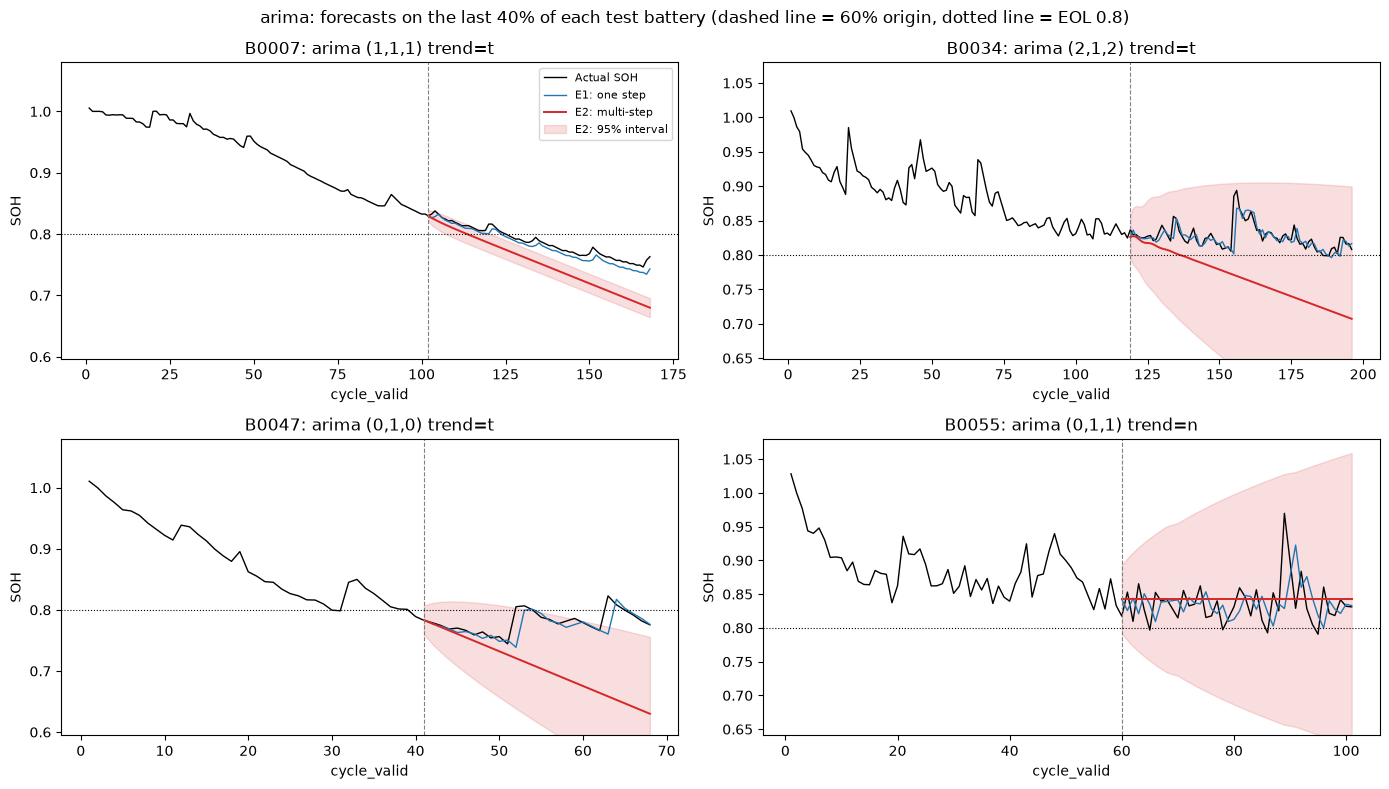

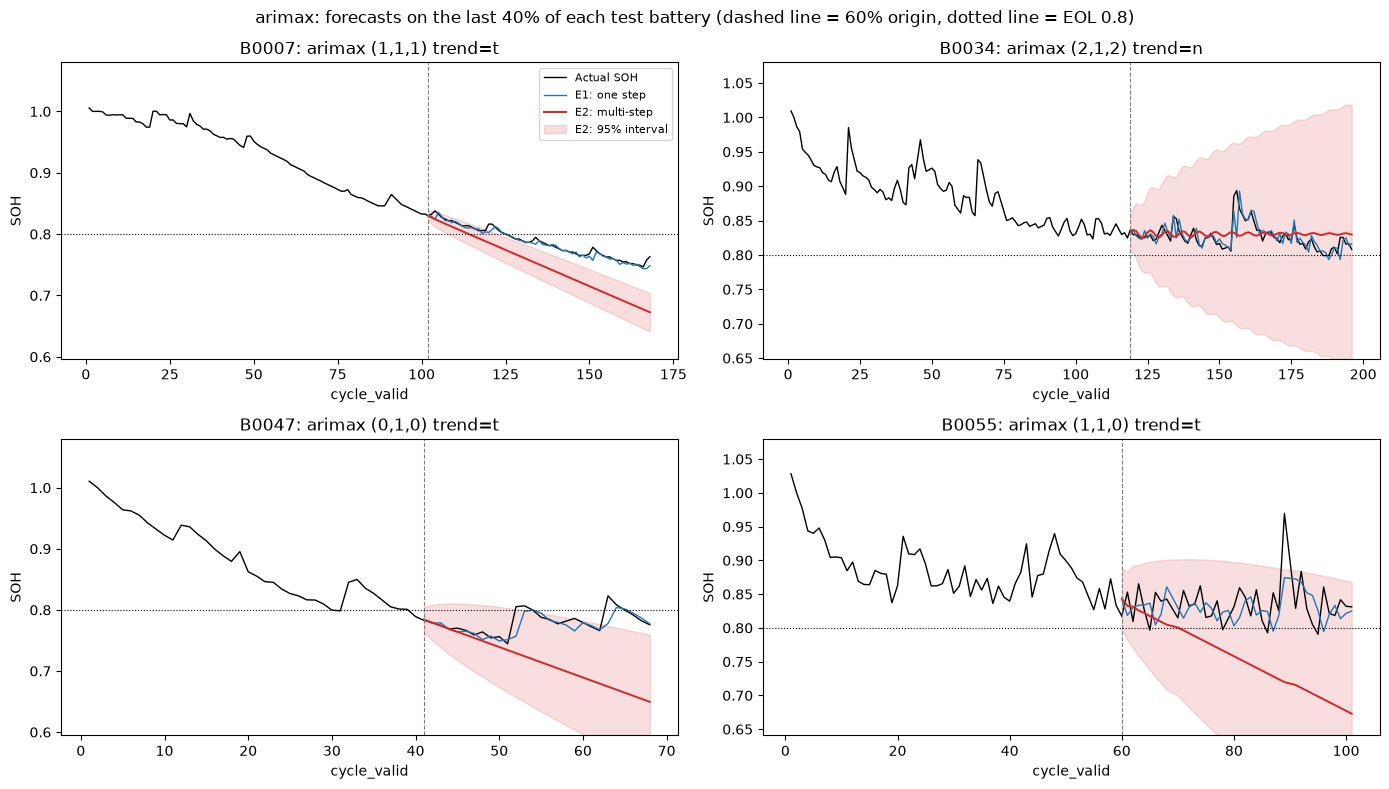

In [19]:
for name in ["arima", "arimax"]:
    fig, axes = plt.subplots(2, 2, figsize=(14, 8))
    for ax, b in zip(axes.flat, TEST_IDS):
        full = rows[rows.battery_id == b]
        p = all_pred[(all_pred.model == name) & (all_pred.battery_id == b)]
        e1, e2 = p[p.scenario == "E1"], p[p.scenario == "E2"]
        ax.plot(full.cycle_valid, full.soh, color="k", lw=1, label="Actual SOH")
        ax.plot(e1.cycle_valid, e1.y_pred, color="tab:blue", lw=1, label="E1: one step")
        ax.plot(e2.cycle_valid, e2.y_pred, color="tab:red", lw=1.4, label="E2: multi-step")
        ax.fill_between(e2.cycle_valid, e2.y_lower, e2.y_upper, color="tab:red", alpha=0.15, label="E2: 95% interval")
        ax.axvline(e1.cycle_valid.min(), color="gray", ls="--", lw=0.8)
        ax.axhline(EOL_SOH, color="k", ls=":", lw=0.8)
        f = fits[(b, name)]
        ax.set_title(f"{b}: {name} ({f['order'][0]},1,{f['order'][2]}) trend={f['trend']}")
        ax.set_ylim(max(0.5, full.soh.min() - 0.15), 1.08)
        ax.set_xlabel("cycle_valid")
        ax.set_ylabel("SOH")
    axes[0, 0].legend(fontsize=8)
    fig.suptitle(f"{name}: forecasts on the last 40% of each test battery (dashed line = 60% origin, dotted line = EOL 0.8)")
    fig.tight_layout()
    fig.savefig(FIG / f"arima_05_forecast_{name}.png", dpi=150)
    plt.show()

## 8. Export the predictions

`reports/predictions/arima.csv` holds two models, `arima` and `arimax` (both exogenous variables, as designed in Go.md 5b.8), each with 213 rows × 2 scenarios.
`arimax_rest` is only used for analysis in this notebook and is not exported, so the shared comparison table is not crowded with variants of one algorithm.
No model is chosen on test results: both pre-specified models are exported. **`arimax` is the main model (Go.md 5b.8); `arima` is the SOH-only reference.**

In [20]:
out = all_pred[all_pred.model.isin(["arima", "arimax"])].sort_values(["model", "scenario"] + KEYS).reset_index(drop=True)
evaluate(out)                           # run the protocol checks again on exactly the file that is written
out.to_csv(PRED / "arima.csv", index=False)
print(f"{len(out)} rows -> {(PRED / 'arima.csv').relative_to(ROOT).as_posix()}")
out.groupby(["model", "scenario"]).size()

852 rows -> reports/predictions/arima.csv


model   scenario
arima   E1          213
        E2          213
arimax  E1          213
        E2          213
dtype: int64

In [21]:
# Key numbers quoted in the conclusions below (read from the tables above, not typed by hand)
fc = spec_table[spec_table.trend == "t"]
print("drift range of test models with trend = t (SOH per cycle):", fc.drift.min().round(5), "to", fc.drift.max().round(5))
print("Ljung-Box pass: train", f"{int(diag.LB_pass.sum())}/{len(diag)}", "| test", f"{int(spec_table.LB_pass.sum())}/{len(spec_table)}")
print("final models converged:", f"{int(orders.converged.sum())}/{len(orders)}")
lr = spec_table[spec_table.model == "arimax_rest"][["battery_id", "coef_log_rest", "p_log_rest"]]
print("arimax_rest log_rest coefficients:\n", lr.round(4).to_string(index=False))
print("\nPooled RMSE / MAE:\n", pooled[["RMSE", "MAE"]].round(4).to_string())
print("\n95% coverage:\n", coverage.coverage_95.round(3).to_string())
print("\nRUL error (E2):\n", rul.pivot(index="model", columns="battery_id", values="rul_error").to_string())

drift range of test models with trend = t (SOH per cycle): -0.00568 to -0.00152
Ljung-Box pass: train 7/8 | test 12/12
final models converged: 20/20
arimax_rest log_rest coefficients:
 battery_id  coef_log_rest  p_log_rest
     B0007         0.0014      0.0193
     B0034         0.0119      0.0000
     B0047         0.0038      0.0000
     B0055         0.0097      0.0000

Pooled RMSE / MAE:
                RMSE             MAE        
scenario         E1      E2      E1      E2
model                                      
naive        0.0226  0.0343  0.0119  0.0249
arima        0.0203  0.0594  0.0114  0.0468
arimax_rest  0.0172  0.0579  0.0108  0.0456
arimax       0.0171  0.0583  0.0098  0.0407

95% coverage:
 model        scenario
arima        E1          0.901
             E2          0.709
arimax       E1          0.920
             E2          0.709
arimax_rest  E1          0.887
             E2          0.681

RUL error (E2):
 battery_id   B0007  B0034  B0055
model                

## 9. Conclusions (RQ3)

The numbers below are read from the tables in sections 4–8 of this notebook (the cell right above prints the key ones).

1. **Box-Jenkins:** every SOH series needs **d = 1**. All selected models have low orders (p, q ≤ 2), and most have a negative drift, i.e. SOH loses on average about
   0.15–0.57 percentage points per cycle (`drift` in section 6). Residuals pass Ljung-Box for 7/8 train batteries and 12/12 test models; the exception is B0018
   (LB p = 0.061 at lag 10 and 0.0003 at lag 20), explained in section 5. Every final model converged (`reports/tables/arima_orders.csv`).
2. **SARIMA is not needed:** there is no common seasonal lag and the gaps between long rests are not constant. The saw-tooth variation caused by regeneration after rest is
   modelled with an exogenous variable instead. In `arimax_rest`, the `log1p(rest_before_h)` coefficient is positive for all 4 test batteries and significant at 5% (section 6).
3. **Fitting differs from the other models.** ARIMA is fitted separately on the first 60% of **each test battery itself**; the 8 train batteries are only used to illustrate
   Box-Jenkins. Regression, SVR and LSTM instead learn from the 8 train batteries and are applied to the test batteries. This matches RQ3 ("only from the battery's own
   history"), and must be stated next to any shared comparison table.
4. **E1 (one step):** all three ARIMA variants have a lower pooled RMSE than naive persistence (0.0203 `arima`, 0.0172 `arimax_rest`, 0.0171 `arimax` vs 0.0226).
   Adding `log1p(rest_before_h)` gives most of the gain, because the model can predict the jump right after a long rest; adding `Rct_ohm` changes RMSE very little but lowers
   MAE (0.0108 → 0.0098). By battery, naive is still better on B0007 (smooth series, few saw-teeth). The 95% intervals of E1 contain 88.7–92.0% of the true values,
   slightly below the nominal 95%.
5. **E2 (multi-step) is ARIMA's weak point:** all three variants are **worse than naive** (pooled MAE 0.0407–0.0468 vs 0.0249) and R² is negative. As Go.md 5b anticipated,
   with d = 1 the long-run forecast is a straight line following the drift estimated on the first 60%, so **the drift decides the E2 result**:
   - B0047: RMSE 0.081–0.092 vs 0.020 for naive. The drift learned on the fast early fade at 4 °C/1 A is extended linearly.
   - B0034: `arima` (drift) RMSE 0.069 vs `arimax` (AIC chose `trend = n`) 0.019.
   - B0055: `arimax` (drift) RMSE 0.099, three times `arima` (no drift) 0.031.

   Adding exogenous variables sometimes helps a lot and sometimes hurts, mostly through which trend AIC picks. The E2 95% intervals are **not** well calibrated:
   they contain only 70.9% (`arima`), 68.1% (`arimax_rest`) and 70.9% (`arimax`) of the true values.
6. **RUL (E2):** `arima` signals EOL **early** on B0007 (−12 cycles) and B0034 (−49) and never reaches 0.8 on B0055. `arimax` is early by 11 cycles on B0007, never reaches 0.8 on
   B0034, and is late by only 6 cycles on B0055. See the RUL table in section 7.

⇒ **Answer to RQ3:** a battery's own history is enough to forecast the **short term** (the next cycle) better than the baseline, especially with rest time as an exogenous variable.
ARIMA is **not** suitable for long-horizon forecasting or RUL, because it is a linear model (Chap 5, p. 51) and cannot capture the "knee" or the flattening of the fade curve.

**Outputs:**
- `reports/predictions/arima.csv`: 852 rows = 2 models (`arima`, `arimax`) × 2 scenarios × 213 evaluation rows, in the `PRED_COLS` format, checked by `evaluate()`.
  `arimax` is the main model (Go.md 5b.8); `arima` is the SOH-only reference.
- `reports/tables/arima_orders.csv`: selected (p, d, q, trend), AIC, convergence and Ljung-Box result of every final model.
- `reports/figures/arima_01_series.png`, `arima_02_acf_level_vs_diff.png`, `arima_03_acf_pacf_diff.png`, `arima_04_resid_acf_train.png`,
  `arima_05_forecast_arima.png`, `arima_05_forecast_arimax.png`.